In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import display, FileLink

# -------------------------
# Parameters
# -------------------------
N = 200
BOX_SIZE = 10.0
DT = 0.05
DIFFUSION = 0.45
REACTION_RADIUS = 0.22
MIN_LIFETIME = 3.0
MAX_LIFETIME = 15.0
FRAMES = 300

rng = np.random.default_rng(42)
attributes = np.array(["A", "B", "C", "D"])
colors = {"A": "red", "B": "blue", "C": "green", "D": "orange"}

# positions, attributes, age, lifetime
positions = rng.uniform(0, BOX_SIZE, size=(N, 2))
attr = rng.choice(attributes, size=N)
age = np.zeros(N)
lifetime = rng.uniform(MIN_LIFETIME, MAX_LIFETIME, size=N)

def step():
    global positions, attr, age, lifetime

    # 2D Brownian motion
    positions += rng.normal(
        0, DIFFUSION * np.sqrt(DT), size=positions.shape
    )
    positions %= BOX_SIZE

    age += DT

    # Natural disappearance
    alive = age < lifetime
    positions = positions[alive]
    attr = attr[alive]
    age = age[alive]
    lifetime = lifetime[alive]

    # Collision/reaction: different attributes -> one of the two disappears
    alive_mask = np.ones(len(positions), dtype=bool)

    for i in range(len(positions)):
        if not alive_mask[i]:
            continue

        candidates = np.where(alive_mask & (attr != attr[i]))[0]
        candidates = candidates[candidates > i]

        if len(candidates) == 0:
            continue

        d = positions[candidates] - positions[i]
        d -= BOX_SIZE * np.round(d / BOX_SIZE)  # periodic distance
        dist2 = np.sum(d*d, axis=1)

        hit = candidates[dist2 < REACTION_RADIUS**2]

        if len(hit) > 0:
            j = rng.choice(hit)
            if rng.random() < 0.5:
                alive_mask[i] = False
            else:
                alive_mask[j] = False

    positions = positions[alive_mask]
    attr = attr[alive_mask]
    age = age[alive_mask]
    lifetime = lifetime[alive_mask]

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(0, BOX_SIZE)
ax.set_ylim(0, BOX_SIZE)
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")

def update(frame):
    step()
    ax.clear()
    ax.set_xlim(0, BOX_SIZE)
    ax.set_ylim(0, BOX_SIZE)
    ax.set_aspect("equal")
    ax.set_xlabel("x")
    ax.set_ylabel("y")

    for a in attributes:
        mask = attr == a
        if np.any(mask):
            ax.scatter(
                positions[mask, 0],
                positions[mask, 1],
                s=28,
                c=colors[a],
                label=a
            )

    ax.legend(loc="upper right")
    ax.set_title(
        f"t = {frame * DT:.2f}   particles = {len(positions)}"
    )

ani = FuncAnimation(fig, update, frames=FRAMES, interval=40)

gif_path = "particle_reaction_2D.gif"
ani.save(gif_path, writer=PillowWriter(fps=25))
plt.close(fig)

print(f"GIFを作成しました: {gif_path}")
display(FileLink(gif_path))


C:\Users\fujdn\AppData\Local\Temp\ipykernel_24976\3143633846.py:104: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="upper right")


GIFを作成しました: particle_reaction_2D.gif


c:\Users\fujdn\Downloads\particle_reaction_2D.gif

In [2]:
ind_prop = random.randint(1, 4)
ind_prop

NameError: name 'random' is not defined

In [1]:

import numpy as np


class GaussianProcessRegression:
    """
    NumPy only の Gaussian Process Regression。

    Parameters
    ----------
    length_scale : float or array-like
        RBFカーネルの長さ尺度。
        floatの場合、全入力変数で共通。
        arrayの場合、入力変数ごとに指定。
    signal_std : float
        カーネルの信号標準偏差。
    noise_std : float
        観測ノイズの標準偏差。
    standardize : bool
        XとYを標準化するかどうか。

    Notes
    -----
    複数出力には対応するが、出力ごとに独立したGPを学習する。
    ハイパーパラメータの自動最適化は行わない。
    """

    def __init__(
        self,
        length_scale=1.0,
        signal_std=1.0,
        noise_std=0.05,
        standardize=True,
    ):
        self.length_scale = np.asarray(
            length_scale, dtype=float
        )
        self.signal_std = float(signal_std)
        self.noise_std = float(noise_std)
        self.standardize = standardize

        if self.signal_std <= 0:
            raise ValueError("signal_std must be positive")
        if self.noise_std < 0:
            raise ValueError("noise_std must be non-negative")
        if np.any(self.length_scale <= 0):
            raise ValueError("length_scale must be positive")

    def _prepare_X(self, X):
        X = np.asarray(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        if X.ndim != 2:
            raise ValueError("X must be a 2D array")

        if not np.all(np.isfinite(X)):
            raise ValueError("X contains NaN or infinity")

        return X

    def _prepare_Y(self, Y):
        Y = np.asarray(Y, dtype=float)

        # 1出力でも内部表現は (N, 1)
        if Y.ndim == 1:
            Y = Y.reshape(-1, 1)

        if Y.ndim != 2:
            raise ValueError("Y must be a 1D or 2D array")

        if not np.all(np.isfinite(Y)):
            raise ValueError("Y contains NaN or infinity")

        return Y

    def _kernel(self, X1, X2):
        """
        ARD RBF kernel:
        k(x, x') = signal_std^2
                   * exp(-0.5 * sum(((x-x')/l)^2))
        """
        # 各入力変数のスケールで距離を調整
        diff = (
            X1[:, None, :] - X2[None, :, :]
        ) / self.length_scale

        squared_distance = np.sum(diff**2, axis=2)

        return (
            self.signal_std**2
            * np.exp(-0.5 * squared_distance)
        )

    def fit(self, X, Y):
        X = self._prepare_X(X)
        Y = self._prepare_Y(Y)

        if len(X) != len(Y):
            raise ValueError("X and Y must have the same number of rows")

        if len(X) == 0:
            raise ValueError("Training data must not be empty")

        self.n_features_in_ = X.shape[1]
        self.n_outputs_ = Y.shape[1]

        # 入力の標準化
        if self.standardize:
            self.X_mean_ = X.mean(axis=0)
            self.X_std_ = X.std(axis=0)
            self.X_std_[self.X_std_ < 1e-12] = 1.0
            Xs = (X - self.X_mean_) / self.X_std_
        else:
            self.X_mean_ = np.zeros(X.shape[1])
            self.X_std_ = np.ones(X.shape[1])
            Xs = X.copy()

        # 出力の標準化（出力ごと）
        if self.standardize:
            self.Y_mean_ = Y.mean(axis=0)
            self.Y_std_ = Y.std(axis=0)
            self.Y_std_[self.Y_std_ < 1e-12] = 1.0
            Ys = (Y - self.Y_mean_) / self.Y_std_
        else:
            self.Y_mean_ = np.zeros(Y.shape[1])
            self.Y_std_ = np.ones(Y.shape[1])
            Ys = Y.copy()

        # length_scale が入力次元と整合するか確認
        if self.length_scale.ndim == 0:
            self.length_scale_ = np.full(
                self.n_features_in_,
                float(self.length_scale),
            )
        else:
            if self.length_scale.shape != (self.n_features_in_,):
                raise ValueError(
                    "length_scale must be a scalar or have "
                    "one value per input feature"
                )
            self.length_scale_ = self.length_scale.copy()

        self.X_train_ = Xs
        self.Y_train_ = Ys

        # 学習カーネル行列
        K = self._kernel(Xs, Xs)

        # 観測ノイズ + 数値安定化のための微小項
        jitter = 1e-10
        K[np.diag_indices_from(K)] += (
            self.noise_std**2 + jitter
        )

        # K = L @ L.T （Cholesky分解）
        self.L_ = np.linalg.cholesky(K)

        # alpha = K^(-1) Y を線形方程式で解く
        tmp = np.linalg.solve(self.L_, Ys)
        self.alpha_ = np.linalg.solve(self.L_.T, tmp)

        return self

    def predict(self, X, return_std=False):
        """
        Parameters
        ----------
        X : array, shape (M, D)
            予測したい入力。
        return_std : bool
            Trueなら予測標準偏差も返す。

        Returns
        -------
        mean : array, shape (M, P)
        std : array, shape (M, P), optional
            潜在関数 f の予測標準偏差。
            観測ノイズを加えた標準偏差ではない。
        """
        if not hasattr(self, "X_train_"):
            raise RuntimeError("Call fit() before predict()")

        X = self._prepare_X(X)

        if X.shape[1] != self.n_features_in_:
            raise ValueError("Incorrect number of input features")

        Xs = (X - self.X_mean_) / self.X_std_

        # 学習点と予測点のカーネル
        K_star = self._kernel(Xs, self.X_train_)

        # 標準化空間での予測平均
        mean_scaled = K_star @ self.alpha_

        # 元の出力スケールに戻す
        mean = mean_scaled * self.Y_std_ + self.Y_mean_

        if not return_std:
            return mean

        # V = L^(-1) K(X_train, X_star)
        V = np.linalg.solve(self.L_, K_star.T)

        # 潜在関数の予測分散
        var_scaled = (
            self.signal_std**2
            - np.sum(V**2, axis=0)
        )

        # 浮動小数点誤差で負になることを防ぐ
        var_scaled = np.maximum(var_scaled, 0.0)

        # 出力ごとの元スケールに変換
        var = var_scaled[:, None] * self.Y_std_[None, :]**2
        std = np.sqrt(var)

        return mean, std


In [4]:

import numpy as np

# 入力: [焼成温度, 焼成時間, 添加剤濃度]
X_train = np.array([
    [800,  1.0, 0.0],
    [850,  1.5, 0.5],
    [900,  2.0, 1.0],
    [950,  1.0, 1.5],
    [850,  2.5, 1.0],
    [900,  1.5, 0.5],
    [950,  2.0, 0.0],
    [800,  2.0, 1.5],
], dtype=float)

# 出力: [導電率, 曲げ強度, 誘電率]
Y_train = np.array([
    [1.2,  80,  12],
    [1.8, 105,  15],
    [2.5, 130,  18],
    [2.1, 110,  22],
    [2.0, 120,  17],
    [2.2, 125,  16],
    [2.4, 115,  14],
    [1.6,  95,  20],
], dtype=float)

# 予測したい条件
X_test = np.array([
    [875, 1.8, 0.8],
    [925, 2.2, 1.2],
], dtype=float)

# GPRモデル
gp = GaussianProcessRegression(
    length_scale=0.2,
    signal_std=0.12,
    noise_std=0.05,
    standardize=True,
)

gp.fit(X_train, Y_train)

# 平均と標準偏差を計算
Y_pred, Y_std = gp.predict(X_test, return_std=True)

output_names = ["導電率", "曲げ強度", "誘電率"]

for i in range(len(X_test)):
    print(f"\n予測条件 {i + 1}: {X_test[i]}")

    for j, name in enumerate(output_names):
        print(
            f"{name}: "
            f"予測値={Y_pred[i, j]:.4f}, "
            f"予測標準偏差={Y_std[i, j]:.4f}"
        )



予測条件 1: [8.75e+02 1.80e+00 8.00e-01]
導電率: 予測値=1.9760, 予測標準偏差=0.0483
曲げ強度: 予測値=110.0372, 予測標準偏差=1.8493
誘電率: 予測値=16.7523, 予測標準偏差=0.3637

予測条件 2: [925.    2.2   1.2]
導電率: 予測値=1.9760, 予測標準偏差=0.0483
曲げ強度: 予測値=110.0370, 予測標準偏差=1.8493
誘電率: 予測値=16.7523, 予測標準偏差=0.3637


In [9]:

"""
Real-data GPR demo using the UCI Concrete Compressive Strength dataset.
GPR implementation uses NumPy only; ucimlrepo is used to download/load data,
and Matplotlib is used for plots.

Install:
    pip install numpy matplotlib ucimlrepo

Run:
    python real_gpr_concrete.py
"""
import numpy as np
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

SEED = 42
TRAIN_SUBSAMPLE = 250  # exact GP scales as O(n^3); use 250 for a quick demo

def standardize_fit(A):
    mean = A.mean(axis=0)
    std = A.std(axis=0)
    std[std < 1e-12] = 1.0
    return mean, std

def standardize_apply(A, mean, std):
    return (A - mean) / std

def rbf_kernel(X1, X2, length_scale=1.0, signal_std=1.0):
    # ARD RBF kernel: one length scale per standardized input feature
    ls = np.asarray(length_scale, dtype=float)
    if ls.ndim == 0:
        ls = np.full(X1.shape[1], float(ls))
    A = X1 / ls
    B = X2 / ls
    d2 = np.maximum(
        (A * A).sum(axis=1)[:, None] + (B * B).sum(axis=1)[None, :] - 2 * A @ B.T,
        0.0
    )
    return signal_std**2 * np.exp(-0.5 * d2)

class NumPyGPR:
    def __init__(self, length_scale=1.0, signal_std=1.0, noise_std=0.12, jitter=1e-8):
        self.length_scale = length_scale
        self.signal_std = signal_std
        self.noise_std = noise_std
        self.jitter = jitter

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_mean = float(np.mean(y))
        self.y_std = float(np.std(y))
        if self.y_std < 1e-12:
            self.y_std = 1.0
        self.y_train = (np.asarray(y, dtype=float).reshape(-1) - self.y_mean) / self.y_std
        K = rbf_kernel(self.X_train, self.X_train, self.length_scale, self.signal_std)
        K += (self.noise_std**2 + self.jitter) * np.eye(len(K))
        self.L = np.linalg.cholesky(K)
        self.alpha = np.linalg.solve(self.L.T, np.linalg.solve(self.L, self.y_train))
        return self

    def predict(self, X, return_std=True):
        X = np.asarray(X, dtype=float)
        Ks = rbf_kernel(X, self.X_train, self.length_scale, self.signal_std)
        mu_std = Ks @ self.alpha
        mu = mu_std * self.y_std + self.y_mean
        if not return_std:
            return mu
        v = np.linalg.solve(self.L, Ks.T)
        var_std = np.maximum(self.signal_std**2 - np.sum(v*v, axis=0), 0.0)
        sigma = np.sqrt(var_std) * self.y_std
        return mu, sigma

def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((y_true - y_pred)**2)))

def main():
    # Fetch public real experimental data from UCI
    ds = fetch_ucirepo(id=165)
    X_df = ds.data.features
    y_df = ds.data.targets
    feature_names = list(X_df.columns)
    X = np.asarray(X_df, dtype=float)
    y = np.asarray(y_df, dtype=float).reshape(-1)

    # Reproducible holdout split; train on a subset so exact GP runs on ordinary laptops
    rng = np.random.default_rng(SEED)
    idx = rng.permutation(len(X))
    n_test = int(round(0.20 * len(X)))
    test_idx = idx[:n_test]
    train_pool = idx[n_test:]
    train_idx = rng.choice(train_pool, size=min(TRAIN_SUBSAMPLE, len(train_pool)), replace=False)

    X_train_raw, y_train = X[train_idx], y[train_idx]
    X_test_raw, y_test = X[test_idx], y[test_idx]

    x_mean, x_std = standardize_fit(X_train_raw)
    X_train = standardize_apply(X_train_raw, x_mean, x_std)
    X_test = standardize_apply(X_test_raw, x_mean, x_std)
    y_scale = np.std(y_train)
    # Standardize y so the noise parameter has a stable scale
    y_mean = np.mean(y_train)
    y_train_std = (y_train - y_mean) / (y_scale if y_scale > 1e-12 else 1.0)

    # A simple fixed-hyperparameter baseline. This is intentionally not optimized.
    model = NumPyGPR(length_scale=1.0, signal_std=1.0, noise_std=0.12)
    model.fit(X_train, y_train)
    pred, pred_std = model.predict(X_test)

    print("Dataset: UCI Concrete Compressive Strength")
    print(f"Rows: {len(X)} | inputs: {X.shape[1]} | train used: {len(train_idx)} | test: {len(test_idx)}")
    print(f"Test RMSE: {rmse(y_test, pred):.2f} MPa")
    print(f"Test MAE: {np.mean(np.abs(y_test-pred)):.2f} MPa")
    print("Note: fixed kernel hyperparameters; this is a demonstration, not a tuned benchmark.")

    # Plot 1: observed vs predicted on held-out test rows
    plt.figure(figsize=(7, 6))
    plt.errorbar(y_test, pred, yerr=1.96*pred_std, fmt='o', alpha=0.55, capsize=2,
                 label='GPR prediction ± 1.96σ')
    lo = min(y_test.min(), pred.min())
    hi = max(y_test.max(), pred.max())
    plt.plot([lo, hi], [lo, hi], '--', label='Ideal: predicted = observed')
    plt.xlabel('Measured compressive strength (MPa)')
    plt.ylabel('Predicted compressive strength (MPa)')
    plt.title('UCI concrete data: GPR predictions on held-out data')
    plt.legend()
    plt.tight_layout()
    plt.savefig('concrete_gpr_pred_vs_measured.png', dpi=180)
    plt.close()

    # Plot 2: age sweep at a representative mixture (median values for other ingredients)
    # Age is swept from 1 to 365 days; remaining inputs are fixed at training medians.
    base = np.median(X_train_raw, axis=0)
    age_col = next((i for i, n in enumerate(feature_names) if 'age' in n.lower()), 7)
    ages = np.linspace(max(1, X[:, age_col].min()), X[:, age_col].max(), 180)
    X_sweep_raw = np.tile(base, (len(ages), 1))
    X_sweep_raw[:, age_col] = ages
    X_sweep = standardize_apply(X_sweep_raw, x_mean, x_std)
    mean_sweep, std_sweep = model.predict(X_sweep)

    plt.figure(figsize=(8, 5))
    plt.plot(ages, mean_sweep, label='GPR mean prediction')
    plt.fill_between(ages, mean_sweep-1.96*std_sweep, mean_sweep+1.96*std_sweep,
                     alpha=0.22, label='Approx. 95% predictive interval')
    plt.scatter(X_train_raw[:, age_col], y_train, s=18, alpha=0.35,
                label='Training measurements (other ingredients vary)')
    plt.xlabel('Age (days)')
    plt.ylabel('Compressive strength (MPa)')
    plt.title('Predicted age trend at a fixed representative mix')
    plt.legend()
    plt.tight_layout()
    plt.savefig('concrete_gpr_age_slice.png', dpi=180)
    plt.close()

    # Plot 3: uncertainty vs age for same fixed mixture
    plt.figure(figsize=(8, 4.5))
    plt.plot(ages, std_sweep)
    plt.xlabel('Age (days)')
    plt.ylabel('Predictive standard deviation (MPa)')
    plt.title('GPR uncertainty along the age sweep')
    plt.tight_layout()
    plt.savefig('concrete_gpr_uncertainty.png', dpi=180)
    plt.close()

    # Save source dataset locally as CSV for reproducibility (NumPy only for model)
    table = np.column_stack([X, y])
    header = ",".join(feature_names + list(y_df.columns))
    np.savetxt('uci_concrete_data.csv', table, delimiter=',', header=header, comments='')
    print("Saved: concrete_gpr_pred_vs_measured.png, concrete_gpr_age_slice.png,")
    print("       concrete_gpr_uncertainty.png, uci_concrete_data.csv")




In [10]:
main()

Dataset: UCI Concrete Compressive Strength
Rows: 1030 | inputs: 8 | train used: 250 | test: 206
Test RMSE: 8.43 MPa
Test MAE: 5.78 MPa
Note: fixed kernel hyperparameters; this is a demonstration, not a tuned benchmark.
Saved: concrete_gpr_pred_vs_measured.png, concrete_gpr_age_slice.png,
       concrete_gpr_uncertainty.png, uci_concrete_data.csv


In [24]:
ds = fetch_ucirepo(id = 165)
df = ds.data.features
df

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360
...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28


In [30]:
df.corr()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
Cement,1.000000,-0.275216,-0.397467,-0.081587,0.092386,-0.109349,-0.222718,0.081946
Blast Furnace Slag,-0.275216,1.000000,-0.323580,0.107252,0.043270,-0.283999,-0.281603,-0.044246
Fly Ash,-0.397467,-0.323580,1.000000,-0.256984,0.377503,-0.009961,0.079108,-0.154371
Water,-0.081587,0.107252,-0.256984,1.000000,-0.657533,-0.182294,-0.450661,0.277618
Superplasticizer,0.092386,0.043270,0.377503,-0.657533,1.000000,-0.265999,0.222691,-0.192700
Coarse Aggregate,-0.109349,-0.283999,-0.009961,-0.182294,-0.265999,1.000000,-0.178481,-0.003016
Fine Aggregate,-0.222718,-0.281603,0.079108,-0.450661,0.222691,-0.178481,1.000000,-0.156095
Age,0.081946,-0.044246,-0.154371,0.277618,-0.192700,-0.003016,-0.156095,1.000000


In [33]:
import numpy as np


class GaussianProcessRegression:
    """
    NumPy only の Gaussian Process Regression。

    Parameters
    ----------
    length_scale : float or array-like
        RBFカーネルの長さ尺度。
        floatの場合、全入力変数で共通。
        arrayの場合、入力変数ごとに指定。
    signal_std : float
        カーネルの信号標準偏差。
    noise_std : float
        観測ノイズの標準偏差。
    standardize : bool
        XとYを標準化するかどうか。

    Notes
    -----
    複数出力には対応するが、出力ごとに独立したGPを学習する。
    ハイパーパラメータの自動最適化は行わない。
    """

    def __init__(
        self,
        length_scale=1.0,
        signal_std=1.0,
        noise_std=0.05,
        standardize=True,
    ):
        self.length_scale = np.asarray(
            length_scale, dtype=float
        )
        self.signal_std = float(signal_std)
        self.noise_std = float(noise_std)
        self.standardize = standardize



    def _prepare_X(self, X):
        X = np.asarray(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        if X.ndim != 2:
            raise ValueError("X must be a 2D array")

        if not np.all(np.isfinite(X)):
            raise ValueError("X contains NaN or infinity")

        return X

    def _prepare_Y(self, Y):
        Y = np.asarray(Y, dtype=float)

        if Y.ndim == 1:
            Y = Y.reshape(-1, 1)

        if Y.ndim != 2:
            raise ValueError("Y must be a 1D or 2D array")

        if not np.all(np.isfinite(Y)):
            raise ValueError("Y contains NaN or infinity")

        return Y

    def _kernel(self, X1, X2):
        diff = (
            X1[:, None, :] - X2[None, :, :]
        ) / np.exp(self.length_scale_)

        squared_distance = np.sum(diff**2, axis=2)

        return (
            np.exp(self.signal_std)**2
            * np.exp(-0.5 * squared_distance)
        )

    def fit(self, X, Y):
        X = self._prepare_X(X)
        Y = self._prepare_Y(Y)

        if len(X) != len(Y):
            raise ValueError("X and Y must have the same number of rows")

        if len(X) == 0:
            raise ValueError("Training data must not be empty")

        self.n_features_in_ = X.shape[1]
        self.n_outputs_ = Y.shape[1]

        if self.standardize:
            self.X_mean_ = X.mean(axis=0)
            self.X_std_ = X.std(axis=0)
            self.X_std_[self.X_std_ < 1e-12] = 1.0
            Xs = (X - self.X_mean_) / self.X_std_
        else:
            self.X_mean_ = np.zeros(X.shape[1])
            self.X_std_ = np.ones(X.shape[1])
            Xs = X.copy()

        if self.standardize:
            self.Y_mean_ = Y.mean(axis=0)
            self.Y_std_ = Y.std(axis=0)
            self.Y_std_[self.Y_std_ < 1e-12] = 1.0
            Ys = (Y - self.Y_mean_) / self.Y_std_
        else:
            self.Y_mean_ = np.zeros(Y.shape[1])
            self.Y_std_ = np.ones(Y.shape[1])
            Ys = Y.copy()

        if self.length_scale.ndim == 0:
            self.length_scale_ = np.full(
                self.n_features_in_,
                float(self.length_scale),
            )
        else:
            if self.length_scale.shape != (self.n_features_in_,):
                raise ValueError(
                    "length_scale must be a scalar or have "
                    "one value per input feature"
                )
            self.length_scale_ = self.length_scale.copy()

        self.X_train_ = Xs
        self.Y_train_ = Ys

        K = self._kernel(Xs, Xs)
        jitter = 1e-10
        K[np.diag_indices_from(K)] += (
            self.noise_std**2 + jitter
        )

        self.L_ = np.linalg.cholesky(K)
        tmp = np.linalg.solve(self.L_, Ys)
        self.alpha_ = np.linalg.solve(self.L_.T, tmp)

        return self

    def predict(self, X, return_std=False):
        if not hasattr(self, "X_train_"):
            raise RuntimeError("Call fit() before predict()")

        X = self._prepare_X(X)

        if X.shape[1] != self.n_features_in_:
            raise ValueError("Incorrect number of input features")

        Xs = (X - self.X_mean_) / self.X_std_
        K_star = self._kernel(Xs, self.X_train_)
        mean_scaled = K_star @ self.alpha_
        mean = mean_scaled * self.Y_std_ + self.Y_mean_

        if not return_std:
            return mean

        V = np.linalg.solve(self.L_, K_star.T)
        var_scaled = self.signal_std**2 - np.sum(V**2, axis=0)
        var_scaled = np.maximum(var_scaled, 0.0)
        var = var_scaled[:, None] * self.Y_std_[None, :]**2
        std = np.sqrt(var)

        return mean, std


import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo


def main():
    # UCI Concrete Compressive Strength dataset (1,030 rows, 8 input features)
    dataset = fetch_ucirepo(id=165)
    X_df = dataset.data.features
    y_df = dataset.data.targets
    feature_names = list(X_df.columns)

    X = X_df.to_numpy(dtype=float)
    y = y_df.to_numpy(dtype=float).reshape(-1)

    # Split into train/test. Use a subset of the training rows because exact GP
    # requires O(N^3) work and O(N^2) memory.
    rng = np.random.default_rng(42)
    indices = rng.permutation(len(X))
    n_test = int(round(0.50 * len(X)))
    test_idx = indices[:n_test]
    train_pool = indices[n_test:]
    n_train = min(250, len(train_pool))
    train_idx = rng.choice(train_pool, size=n_train, replace=False)

    X_train, y_train = X[train_idx], y[train_idx]
    X_test, y_test = X[test_idx], y[test_idx]

    # Your class standardizes X and Y internally.
    # noise_std is specified in standardized Y units because standardize=True.
    model = GaussianProcessRegression(
        length_scale=-0.5,
        signal_std=-1.0,
        noise_std=0.05,
        standardize=True,
    )
    model.fit(X_train, y_train)
    y_pred, y_std = model.predict(X_test, return_std=True)

    rmse = np.sqrt(np.mean((y_test - y_pred[:, 0]) ** 2))
    mae = np.mean(np.abs(y_test - y_pred[:, 0]))
    print("UCI Concrete Compressive Strength")
    print(f"All rows: {len(X)}")
    print(f"Training rows used: {len(train_idx)}")
    print(f"Test rows: {len(test_idx)}")
    print(f"Test RMSE: {rmse:.3f} MPa")
    print(f"Test MAE:  {mae:.3f} MPa")
    print("Features:", ", ".join(feature_names))
    print("Kernel hyperparameters are fixed, not optimized.")

    # 1. Measured vs predicted strength with approximate 95% latent-function interval
    plt.figure(figsize=(7, 6))
    plt.errorbar(
        y_test, y_pred[:, 0], yerr=1.96 * y_std[:, 0],
        fmt="o", alpha=0.55, capsize=2, label="GPR mean ± 1.96σ"
    )
    lo = min(float(y_test.min()), float(y_pred.min()))
    hi = max(float(y_test.max()), float(y_pred.max()))
    plt.plot([lo, hi], [lo, hi], "--", label="Ideal prediction")
    plt.xlabel("Measured compressive strength (MPa)")
    plt.ylabel("Predicted compressive strength (MPa)")
    plt.title("UCI concrete data: measured vs GPR prediction")
    plt.legend()
    plt.tight_layout()
    plt.savefig("concrete_measured_vs_predicted.png", dpi=180)
    plt.close()

    # 2. Test-set comparison by sample: measured vs predicted, plus residuals.
    # Sort by measured strength so the agreement is easier to inspect.
    order = np.argsort(y_test)
    measured_sorted = y_test[order]
    predicted_sorted = y_pred[order, 0]
    residual_sorted = predicted_sorted - measured_sorted
    sample_no = np.arange(1, len(y_test) + 1)

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(10, 7), sharex=True,
        gridspec_kw={"height_ratios": [2, 1]}
    )
    ax1.plot(sample_no, measured_sorted, "o-", markersize=3,
             linewidth=1, label="Measured test values")
    ax1.plot(sample_no, predicted_sorted, "o-", markersize=3,
             linewidth=1, label="GPR predictions")
    ax1.set_ylabel("Compressive strength (MPa)")
    ax1.set_title("Test-set comparison (sorted by measured strength)")
    ax1.legend()
    ax1.grid(True, alpha=0.25)

    ax2.axhline(0, linestyle="--", linewidth=1)
    ax2.plot(sample_no, residual_sorted, "o", markersize=3)
    ax2.set_xlabel("Test samples (sorted by measured strength)")
    ax2.set_ylabel("Residual (predicted − measured, MPa)")
    ax2.grid(True, alpha=0.25)
    fig.tight_layout()
    fig.savefig("concrete_test_set_comparison.png", dpi=180)
    plt.close(fig)

    # 3. Age slice: vary age while fixing other ingredients at training medians.
    age_idx = next((i for i, name in enumerate(feature_names)
                    if "age" in name.lower()), 7)
    base = np.median(X_train, axis=0)
    age_min = max(1.0, float(X[:, age_idx].min()))
    age_max = float(X[:, age_idx].max())
    ages = np.linspace(age_min, age_max, 180)
    X_slice = np.tile(base, (len(ages), 1))
    X_slice[:, age_idx] = ages

    slice_mean, slice_std = model.predict(X_slice, return_std=True)
    plt.figure(figsize=(8, 5))
    plt.plot(ages, slice_mean[:, 0], label="GPR mean")
    plt.fill_between(
        ages,
        slice_mean[:, 0] - 1.96 * slice_std[:, 0],
        slice_mean[:, 0] + 1.96 * slice_std[:, 0],
        alpha=0.22, label="Approx. 95% interval"
    )
    # These points have different mixtures, so are context only—not a direct
    # comparison against the fixed-mixture curve.
    plt.scatter(
        X_train[:, age_idx], y_train, s=16, alpha=0.28,
        label="Training data (mixtures vary)"
    )
    plt.xlabel("Age (days)")
    plt.ylabel("Compressive strength (MPa)")
    plt.title("Age effect at a representative fixed mixture")
    plt.legend()
    plt.tight_layout()
    plt.savefig("concrete_age_slice.png", dpi=180)
    plt.close()

    # 3. Predictive uncertainty across the age slice
    plt.figure(figsize=(8, 4.5))
    plt.plot(ages, slice_std[:, 0])
    plt.xlabel("Age (days)")
    plt.ylabel("Predictive standard deviation (MPa)")
    plt.title("GPR uncertainty along the age slice")
    plt.tight_layout()
    plt.savefig("concrete_age_uncertainty.png", dpi=180)
    plt.close()

    # Save predictions for the held-out test set
    np.savetxt(
        "concrete_test_predictions.csv",
        np.column_stack([y_test, y_pred[:, 0], y_std[:, 0]]),
        delimiter=",",
        header="measured_MPa,predicted_MPa,predictive_std_MPa",
        comments="",
    )
    print("Saved: concrete_measured_vs_predicted.png,")
    print("       concrete_test_set_comparison.png,")
    print("       concrete_age_slice.png, concrete_age_uncertainty.png,")
    print("       concrete_test_predictions.csv")

main()

UCI Concrete Compressive Strength
All rows: 1030
Training rows used: 250
Test rows: 515
Test RMSE: 11.392 MPa
Test MAE:  8.323 MPa
Features: Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, Age
Kernel hyperparameters are fixed, not optimized.
Saved: concrete_measured_vs_predicted.png,
       concrete_test_set_comparison.png,
       concrete_age_slice.png, concrete_age_uncertainty.png,
       concrete_test_predictions.csv


In [35]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)
from ucimlrepo import fetch_ucirepo


# ============================================================
# 0. 設定
# ============================================================

RANDOM_STATE = 42

# データセットの分割
TEST_SIZE = 0.20
VALIDATION_SIZE = 0.25  # 残り80%のうち25%を検証用にする

# GPRのハイパーパラメータ
LENGTH_SCALE = 1.0
SIGNAL_STD = 1.0
NOISE_STD = 0.05

# 出力先
OUTPUT_DIR = Path("concrete_gpr_feature_selection_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 1. Gaussian Process Regression クラス
#    NumPyのみで実装
# ============================================================

class GaussianProcessRegression:
    """
    RBFカーネルを用いたガウス過程回帰。

    Parameters
    ----------
    length_scale : float or array-like
        RBFカーネルの長さ尺度。
        配列の場合は特徴量ごとの長さ尺度として使用する。
    signal_std : float
        カーネルの信号標準偏差。
    noise_std : float
        観測ノイズの標準偏差。
    standardize : bool
        XとYを標準化するかどうか。
    """

    def __init__(
        self,
        length_scale=1.0,
        signal_std=1.0,
        noise_std=0.05,
        standardize=True,
    ):
        self.length_scale = np.asarray(
            length_scale, dtype=float
        )
        self.signal_std = float(signal_std)
        self.noise_std = float(noise_std)
        self.standardize = standardize

        self.is_fitted = False

    def _prepare_X(self, X, fitting=False):
        X = np.asarray(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        if fitting:
            self.X_mean_ = np.mean(X, axis=0)
            self.X_std_ = np.std(X, axis=0)
            self.X_std_[self.X_std_ < 1e-12] = 1.0

        if self.standardize:
            return (X - self.X_mean_) / self.X_std_

        return X.copy()

    def _prepare_Y(self, Y, fitting=False):
        Y = np.asarray(Y, dtype=float)

        if Y.ndim == 1:
            Y = Y.reshape(-1, 1)

        if fitting:
            self.Y_mean_ = np.mean(Y, axis=0)
            self.Y_std_ = np.std(Y, axis=0)
            self.Y_std_[self.Y_std_ < 1e-12] = 1.0

        if self.standardize:
            return (Y - self.Y_mean_) / self.Y_std_

        return Y.copy()

    def _kernel(self, X1, X2):
        """
        ARD対応RBFカーネル。
        各特徴量の長さ尺度が異なる場合にも対応する。
        """
        length_scale = self.length_scale

        if length_scale.ndim == 0:
            length_scale = np.full(
                X1.shape[1], float(length_scale)
            )

        if length_scale.size != X1.shape[1]:
            raise ValueError(
                "length_scaleの要素数が特徴量数と一致しません。"
            )

        length_scale = np.maximum(length_scale, 1e-12)

        X1_scaled = X1 / length_scale
        X2_scaled = X2 / length_scale

        sq_norm_1 = np.sum(X1_scaled**2, axis=1)[:, None]
        sq_norm_2 = np.sum(X2_scaled**2, axis=1)[None, :]

        squared_distance = (
            sq_norm_1 + sq_norm_2
            - 2.0 * X1_scaled @ X2_scaled.T
        )

        squared_distance = np.maximum(squared_distance, 0.0)

        return (
            self.signal_std**2
            * np.exp(-0.5 * squared_distance)
        )

    def fit(self, X, Y):
        X = np.asarray(X, dtype=float)
        Y = np.asarray(Y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        self.y_was_1d_ = Y.ndim == 1

        X_scaled = self._prepare_X(X, fitting=True)
        Y_scaled = self._prepare_Y(Y, fitting=True)

        self.X_train_ = X_scaled
        self.Y_train_ = Y_scaled

        K = self._kernel(X_scaled, X_scaled)

        # 数値計算を安定させるための微小項
        jitter = 1e-8

        # 観測ノイズの分散を対角に加える
        K = K + (
            self.noise_std**2 + jitter
        ) * np.eye(len(X_scaled))

        # K = L L^T
        self.L_ = np.linalg.cholesky(K)

        # alpha = K^{-1}Y を直接逆行列を作らずに計算
        tmp = np.linalg.solve(self.L_, Y_scaled)
        self.alpha_ = np.linalg.solve(
            self.L_.T, tmp
        )

        self.is_fitted = True
        return self

    def predict(self, X, return_std=False):
        if not self.is_fitted:
            raise RuntimeError(
                "先にfit()を実行してください。"
            )

        X = np.asarray(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_scaled = self._prepare_X(X, fitting=False)

        K_star = self._kernel(
            X_scaled, self.X_train_
        )

        # 予測平均
        mean_scaled = K_star @ self.alpha_

        if self.standardize:
            mean = (
                mean_scaled * self.Y_std_
                + self.Y_mean_
            )
        else:
            mean = mean_scaled

        if not return_std:
            return mean.ravel() if self.y_was_1d_ else mean

        # 潜在関数の予測分散
        v = np.linalg.solve(
            self.L_, K_star.T
        )

        variance_scaled = (
            self.signal_std**2
            - np.sum(v**2, axis=0)
        )

        variance_scaled = np.maximum(
            variance_scaled, 0.0
        )

        if self.standardize:
            variance = (
                variance_scaled[:, None]
                * self.Y_std_[None, :]**2
            )
        else:
            variance = variance_scaled[:, None]

        std = np.sqrt(variance)

        if self.y_was_1d_:
            return mean.ravel(), std.ravel()

        return mean, std


# ============================================================
# 2. データセット取得
# ============================================================

print("データセットを取得しています...")

dataset = fetch_ucirepo(id=165)

X_df = dataset.data.features.copy()
Y_df = dataset.data.targets.copy()

# 列名を文字列に統一
X_df.columns = X_df.columns.astype(str)
Y_df.columns = Y_df.columns.astype(str)

# 欠損値があれば除去
data = pd.concat([X_df, Y_df], axis=1)
data = data.dropna()

X_df = data[X_df.columns]
target_name = Y_df.columns[0]
y = data[target_name].to_numpy(dtype=float)

feature_names = list(X_df.columns)
X = X_df.to_numpy(dtype=float)

print(f"データ数: {len(X)}")
print(f"特徴量数: {len(feature_names)}")
print(f"目的変数: {target_name}")
print("特徴量:", feature_names)


# ============================================================
# 3. 学習・検証・テストデータに分割
# ============================================================

# 最初にテストデータを分離
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

# 学習用と検証用に分割
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval,
    y_trainval,
    test_size=VALIDATION_SIZE,
    random_state=RANDOM_STATE,
)

print("\nデータ分割")
print(f"学習用: {len(X_train)}")
print(f"検証用: {len(X_val)}")
print(f"テスト用: {len(X_test)}")


# ============================================================
# 4. GPRを作成する関数
# ============================================================

def create_gpr():
    return GaussianProcessRegression(
        length_scale=LENGTH_SCALE,
        signal_std=SIGNAL_STD,
        noise_std=NOISE_STD,
        standardize=True,
    )


def calculate_metrics(y_true, y_pred):
    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return {
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
    }


# ============================================================
# 5. 全特徴量でGPRを学習
# ============================================================

print("\n全特徴量でGPRを学習しています...")

gpr_all = create_gpr()
gpr_all.fit(X_train, y_train)

y_val_pred_all = gpr_all.predict(X_val)

all_metrics = calculate_metrics(
    y_val, y_val_pred_all
)

print("\n全特徴量モデルの検証性能")
print(f"RMSE: {all_metrics['RMSE']:.4f} MPa")
print(f"MAE : {all_metrics['MAE']:.4f} MPa")
print(f"R²  : {all_metrics['R2']:.4f}")


# ============================================================
# 6. Permutation Importance
# ============================================================

print("\n特徴量の重要度を計算しています...")

# 重要度計算用のモデルは学習用データだけで学習する
gpr_importance = create_gpr()
gpr_importance.fit(X_train, y_train)

# シャッフル前の検証RMSE
baseline_pred = gpr_importance.predict(X_val)
baseline_rmse = np.sqrt(
    mean_squared_error(y_val, baseline_pred)
)

rng = np.random.default_rng(RANDOM_STATE)

importance_records = []

# 各特徴量を独立にシャッフル
# 1回のシャッフルによる偶然の影響を減らすため複数回実施
N_REPEATS = 10

for j, feature_name in enumerate(feature_names):
    rmse_increases = []

    for _ in range(N_REPEATS):
        X_val_permuted = X_val.copy()

        shuffled_values = X_val_permuted[:, j].copy()
        rng.shuffle(shuffled_values)
        X_val_permuted[:, j] = shuffled_values

        y_perm_pred = gpr_importance.predict(
            X_val_permuted
        )

        permuted_rmse = np.sqrt(
            mean_squared_error(y_val, y_perm_pred)
        )

        rmse_increases.append(
            permuted_rmse - baseline_rmse
        )

    importance_records.append({
        "feature": feature_name,
        "importance_mean": np.mean(rmse_increases),
        "importance_std": np.std(rmse_increases),
    })

importance_df = pd.DataFrame(
    importance_records
).sort_values(
    "importance_mean", ascending=False
).reset_index(drop=True)

importance_df.to_csv(
    OUTPUT_DIR / "feature_importance.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\n特徴量重要度ランキング")
print(importance_df.to_string(index=False))


# ============================================================
# 7. 重要度ランキングを可視化
# ============================================================

plt.figure(figsize=(10, 6))

sorted_importance = importance_df.sort_values(
    "importance_mean", ascending=True
)

plt.barh(
    sorted_importance["feature"],
    sorted_importance["importance_mean"],
    xerr=sorted_importance["importance_std"],
)

plt.axvline(
    0.0,
    linewidth=1,
)

plt.xlabel("Increase in validation RMSE (MPa)")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance for GPR")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "feature_importance.png",
    dpi=200,
)
plt.close()


# ============================================================
# 8. 上位1～8特徴量でモデルを比較
# ============================================================

ranked_features = importance_df["feature"].tolist()

# 特徴量名から元データの列番号を取得
feature_to_index = {
    name: i for i, name in enumerate(feature_names)
}

ranked_indices = [
    feature_to_index[name]
    for name in ranked_features
]

comparison_records = []

print("\n特徴量数ごとの検証性能を比較しています...")

for k in range(1, len(feature_names) + 1):
    selected_indices = ranked_indices[:k]
    selected_names = [
        feature_names[i] for i in selected_indices
    ]

    X_train_k = X_train[:, selected_indices]
    X_val_k = X_val[:, selected_indices]

    model_k = create_gpr()
    model_k.fit(X_train_k, y_train)

    y_val_pred_k = model_k.predict(X_val_k)

    metrics = calculate_metrics(
        y_val, y_val_pred_k
    )

    comparison_records.append({
        "n_features": k,
        "features": ", ".join(selected_names),
        "RMSE": metrics["RMSE"],
        "MAE": metrics["MAE"],
        "R2": metrics["R2"],
    })

comparison_df = pd.DataFrame(
    comparison_records
)

comparison_df.to_csv(
    OUTPUT_DIR / "feature_count_comparison.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\n特徴量数ごとの検証結果")
print(
    comparison_df[
        ["n_features", "RMSE", "MAE", "R2"]
    ].to_string(index=False)
)


# ============================================================
# 9. 検証RMSEが最小となる特徴量数を選ぶ
# ============================================================

best_row_index = comparison_df["RMSE"].idxmin()
best_row = comparison_df.loc[best_row_index]

best_k = int(best_row["n_features"])
selected_features = ranked_features[:best_k]
selected_indices = [
    feature_to_index[name]
    for name in selected_features
]

print("\n選択された特徴量")
print(f"特徴量数: {best_k}")
for i, name in enumerate(selected_features, start=1):
    print(f"{i}. {name}")

print(
    f"\n最小検証RMSE: {best_row['RMSE']:.4f} MPa"
)


# ============================================================
# 10. 選択した特徴量で再学習
#     学習用 + 検証用データをまとめて使用
# ============================================================

X_trainval_selected = X_trainval[:, selected_indices]
X_test_selected = X_test[:, selected_indices]

final_gpr = create_gpr()
final_gpr.fit(
    X_trainval_selected,
    y_trainval,
)

y_test_pred, y_test_std = final_gpr.predict(
    X_test_selected,
    return_std=True,
)

test_metrics = calculate_metrics(
    y_test, y_test_pred
)

print("\n===================================")
print("最終モデルのテストデータ評価")
print("===================================")
print(f"使用特徴量数: {best_k}")
print(f"RMSE: {test_metrics['RMSE']:.4f} MPa")
print(f"MAE : {test_metrics['MAE']:.4f} MPa")
print(f"R²  : {test_metrics['R2']:.4f}")


# ============================================================
# 11. 全特徴量モデルも同じテストデータで評価
# ============================================================

final_gpr_all = create_gpr()
final_gpr_all.fit(
    X_trainval,
    y_trainval,
)

y_test_pred_all = final_gpr_all.predict(X_test)

all_test_metrics = calculate_metrics(
    y_test, y_test_pred_all
)

test_comparison = pd.DataFrame([
    {
        "model": "All features",
        "n_features": len(feature_names),
        **all_test_metrics,
    },
    {
        "model": "Selected features",
        "n_features": best_k,
        **test_metrics,
    },
])

test_comparison.to_csv(
    OUTPUT_DIR / "final_test_comparison.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\n全特徴量モデルと特徴量選択モデルの比較")
print(test_comparison.to_string(index=False))


# ============================================================
# 12. テストデータの予測値をCSV保存
# ============================================================

prediction_df = pd.DataFrame({
    "actual_strength": y_test,
    "predicted_strength": y_test_pred,
    "predictive_std": y_test_std,
    "residual": y_test - y_test_pred,
})

prediction_df.to_csv(
    OUTPUT_DIR / "test_predictions.csv",
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# 13. 特徴量数とRMSEの関係を可視化
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    comparison_df["n_features"],
    comparison_df["RMSE"],
    marker="o",
)

plt.xticks(
    range(1, len(feature_names) + 1)
)

plt.xlabel("Number of selected features")
plt.ylabel("Validation RMSE (MPa)")
plt.title("GPR Performance vs Number of Features")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "rmse_vs_feature_count.png",
    dpi=200,
)
plt.close()


# ============================================================
# 14. テストデータ：実測値 vs 予測値
# ============================================================

plt.figure(figsize=(6, 6))

plt.scatter(
    y_test,
    y_test_pred,
    alpha=0.7,
)

min_value = min(
    np.min(y_test),
    np.min(y_test_pred),
)

max_value = max(
    np.max(y_test),
    np.max(y_test_pred),
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
)

plt.xlabel("Measured strength (MPa)")
plt.ylabel("Predicted strength (MPa)")
plt.title("Selected-Feature GPR: Test Data")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "test_measured_vs_predicted.png",
    dpi=200,
)
plt.close()


# ============================================================
# 15. テストデータ：実測値と予測値の比較
# ============================================================

plt.figure(figsize=(12, 5))

n_show = min(100, len(y_test))
order = np.argsort(y_test[:n_show])

plt.plot(
    np.arange(n_show),
    y_test[:n_show][order],
    marker="o",
    label="Measured",
)

plt.plot(
    np.arange(n_show),
    y_test_pred[:n_show][order],
    marker="x",
    label="Predicted",
)

plt.xlabel("Test sample (sorted by measured strength)")
plt.ylabel("Compressive strength (MPa)")
plt.title("Measured vs Predicted Strength")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "test_set_comparison.png",
    dpi=200,
)
plt.close()


# ============================================================
# 16. 残差プロット
# ============================================================

residuals = y_test - y_test_pred

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test_pred,
    residuals,
    alpha=0.7,
)

plt.axhline(
    0.0,
    linestyle="--",
)

plt.xlabel("Predicted strength (MPa)")
plt.ylabel("Residual (Measured - Predicted, MPa)")
plt.title("Residual Plot")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "residual_plot.png",
    dpi=200,
)
plt.close()


# ============================================================
# 17. 予測不確かさの可視化
# ============================================================

plt.figure(figsize=(10, 5))

sample_order = np.argsort(y_test_pred)

plt.errorbar(
    np.arange(len(y_test)),
    y_test_pred[sample_order],
    yerr=1.96 * y_test_std[sample_order],
    fmt="o",
    markersize=3,
    capsize=2,
    label="Prediction ± 1.96 std",
)

plt.scatter(
    np.arange(len(y_test)),
    y_test[sample_order],
    marker="x",
    label="Measured",
)

plt.xlabel("Test sample (sorted by prediction)")
plt.ylabel("Compressive strength (MPa)")
plt.title("GPR Prediction and Uncertainty")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "prediction_uncertainty.png",
    dpi=200,
)
plt.close()


# ============================================================
# 18. 選択結果を保存
# ============================================================

with open(
    OUTPUT_DIR / "selected_features.txt",
    "w",
    encoding="utf-8",
) as f:
    f.write(f"Selected feature count: {best_k}\n")
    f.write(f"Validation RMSE: {best_row['RMSE']:.6f} MPa\n")
    f.write("\nSelected features:\n")

    for name in selected_features:
        f.write(f"- {name}\n")

print("\n処理が完了しました。")
print(f"出力フォルダ: {OUTPUT_DIR.resolve()}")
print("主な出力ファイル:")
print("- feature_importance.csv")
print("- feature_importance.png")
print("- feature_count_comparison.csv")
print("- final_test_comparison.csv")
print("- test_predictions.csv")
print("- rmse_vs_feature_count.png")
print("- test_measured_vs_predicted.png")
print("- test_set_comparison.png")
print("- residual_plot.png")
print("- prediction_uncertainty.png")
print("- selected_features.txt")


データセットを取得しています...
データ数: 1030
特徴量数: 8
目的変数: Concrete compressive strength
特徴量: ['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer', 'Coarse Aggregate', 'Fine Aggregate', 'Age']

データ分割
学習用: 618
検証用: 206
テスト用: 206

全特徴量でGPRを学習しています...

全特徴量モデルの検証性能
RMSE: 6.6212 MPa
MAE : 4.2511 MPa
R²  : 0.8562

特徴量の重要度を計算しています...

特徴量重要度ランキング
           feature  importance_mean  importance_std
               Age         8.468125        0.651901
            Cement         6.798648        0.413943
  Superplasticizer         5.477365        0.350633
             Water         4.794095        0.416691
  Coarse Aggregate         3.976124        0.235208
Blast Furnace Slag         3.960975        0.461868
           Fly Ash         3.872828        0.403350
    Fine Aggregate         3.136102        0.318976

特徴量数ごとの検証性能を比較しています...

特徴量数ごとの検証結果
 n_features      RMSE       MAE       R2
          1 14.080312 11.122647 0.349823
          2 10.287804  8.190978 0.652902
          3  8.175155  6.1

In [38]:
import pandas as pd

# UCIから赤ワイン・白ワインのデータを取得
base_url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/wine-quality/"
)

red = pd.read_csv(base_url + "winequality-red.csv", sep=";")
white = pd.read_csv(base_url + "winequality-white.csv", sep=";")

# カテゴリ変数を追加
red["wine_type"] = "red"
white["wine_type"] = "white"

# 1つのデータセットに統合
data = pd.concat([red, white], ignore_index=True)

# CSVに保存
data.to_csv("wine_quality.csv", index=False, encoding="utf-8-sig")

print(data.head())
print(data.shape)

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality wine_type  
0      9.4        5       red  
1      9.8        5   

In [39]:
data

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,white
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,white
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,white
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,white


In [43]:

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    RBF, ConstantKernel, WhiteKernel
)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

warnings.filterwarnings("ignore")

# ============================================================
# 1. データの読み込み
# ============================================================

if os.path.exists("wine_quality.csv"):
    data = pd.read_csv("wine_quality.csv")
else:
    base_url = (
        "https://archive.ics.uci.edu/ml/"
        "machine-learning-databases/wine-quality/"
    )

    red = pd.read_csv(
        base_url + "winequality-red.csv", sep=";"
    )
    white = pd.read_csv(
        base_url + "winequality-white.csv", sep=";"
    )

    red["wine_type"] = "red"
    white["wine_type"] = "white"

    data = pd.concat([red, white], ignore_index=True)
    data.to_csv(
        "wine_quality.csv", index=False, encoding="utf-8-sig"
    )

data = data.dropna().copy()

print("データ件数:", len(data))
data

データ件数: 6497


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,white
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,white
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,white
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,white


In [44]:

# ============================================================
# 2. 計算負荷を抑えるためにサンプリング
# ============================================================

RANDOM_STATE = 42
N_SAMPLES = min(1200, len(data))

data = data.sample(
    n=N_SAMPLES, random_state=RANDOM_STATE
).reset_index(drop=True)

# 予測対象
y = data["quality"].astype(float)

# 説明変数
X = data.drop(columns=["quality"])

# ============================================================
# 3. 学習データとテストデータに分割
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

# 数値列とカテゴリ列を自動判定
numeric_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("\n数値特徴量:", numeric_cols)
print("カテゴリ特徴量:", categorical_cols)

# ============================================================
# 4. One-Hot Encoding
#    エンコーダは学習データだけでfitする
# ============================================================

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

if categorical_cols:
    X_train_cat = encoder.fit_transform(
        X_train[categorical_cols]
    )
    X_test_cat = encoder.transform(
        X_test[categorical_cols]
    )

    cat_feature_names = encoder.get_feature_names_out(
        categorical_cols
    ).tolist()
else:
    X_train_cat = np.empty((len(X_train), 0))
    X_test_cat = np.empty((len(X_test), 0))
    cat_feature_names = []

X_train_num = X_train[numeric_cols].to_numpy(dtype=float)
X_test_num = X_test[numeric_cols].to_numpy(dtype=float)

# 数値特徴量は学習データの平均・標準偏差で標準化
scaler = StandardScaler()

X_train_num = scaler.fit_transform(X_train_num)
X_test_num = scaler.transform(X_test_num)

# 数値列とOne-Hot列を結合
X_train_encoded = np.hstack(
    [X_train_num, X_train_cat]
)
X_test_encoded = np.hstack(
    [X_test_num, X_test_cat]
)

feature_names = numeric_cols + cat_feature_names

X_train_encoded = pd.DataFrame(
    X_train_encoded, columns=feature_names,
    index=X_train.index
)
X_test_encoded = pd.DataFrame(
    X_test_encoded, columns=feature_names,
    index=X_test.index
)

print("\nOne-Hot Encoding後の特徴量数:",
      len(feature_names))
print("変換後のデータ形状:", X_train_encoded.shape)



数値特徴量: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
カテゴリ特徴量: ['wine_type']

One-Hot Encoding後の特徴量数: 13
変換後のデータ形状: (960, 13)


In [45]:

# ============================================================
# 5. 特徴量選別
#    F検定によってqualityとの関連が強い特徴量を選ぶ
# ============================================================

# 選択する特徴量数
N_FEATURES = min(4, X_train_encoded.shape[1])

selector = SelectKBest(
    score_func=f_regression,
    k=N_FEATURES
)

X_train_selected = selector.fit_transform(
    X_train_encoded, y_train
)
X_test_selected = selector.transform(
    X_test_encoded
)

selected_mask = selector.get_support()
selected_features = np.array(feature_names)[selected_mask]

# F値をランキングとして表示
scores = selector.scores_
scores = np.nan_to_num(
    scores, nan=0.0, posinf=0.0, neginf=0.0
)

feature_ranking = pd.DataFrame({
    "feature": feature_names,
    "F_score": scores,
    "selected": selected_mask
}).sort_values("F_score", ascending=False)

print("\n===== 特徴量ランキング =====")
print(feature_ranking.to_string(index=False))

print("\n===== 選別された特徴量 =====")
for name in selected_features:
    print(name)



===== 特徴量ランキング =====
             feature    F_score  selected
             alcohol 208.908067      True
             density 106.362977      True
    volatile acidity  75.230819      True
           chlorides  50.876580      True
       wine_type_red  21.387419     False
     wine_type_white  21.387419     False
       fixed acidity  14.843006     False
         citric acid   7.699270     False
 free sulfur dioxide   0.162952     False
total sulfur dioxide   0.127865     False
                  pH   0.106864     False
           sulphates   0.043844     False
      residual sugar   0.014731     False

===== 選別された特徴量 =====
volatile acidity
chlorides
density
alcohol


In [47]:

import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# 1. データ取得
dataset = fetch_openml(
    name="Bike_Sharing_Demand",
    version=2,
    as_frame=True
)

df = dataset.frame.copy()

print("データ形状:", df.shape)
print("列名:", df.columns.tolist())
print(df.head())

# 2. 目的変数を確認
# データセットの版によって列名が異なる場合がある
target_candidates = ["count", "cnt"]

target_col = next(
    (c for c in target_candidates if c in df.columns),
    None
)

if target_col is None:
    print("目的変数を確認してください。")
    print(df.columns.tolist())
    raise ValueError("count / cnt 列が見つかりません")

y = pd.to_numeric(df[target_col], errors="coerce")
X = df.drop(columns=[target_col])

# 3. 整数で格納されたカテゴリ変数もカテゴリ扱いにする
possible_categories = [
    "season", "year", "month", "hour",
    "holiday", "weekday", "workingday",
    "weather", "weather_main"
]

categorical_cols = [
    c for c in possible_categories if c in X.columns
]

# 文字列列もカテゴリ変数に追加
categorical_cols += [
    c for c in X.select_dtypes(
        include=["object", "category", "string"]
    ).columns
    if c not in categorical_cols
]

numeric_cols = [
    c for c in X.columns if c not in categorical_cols
]

# 欠損した目的変数を除去
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid]

# 4. 学習・テスト分割
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. 数値列とカテゴリ列を別々に前処理
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# 学習データで変換器を学習
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("\n数値列:", numeric_cols)
print("カテゴリ列:", categorical_cols)
print("変換後の学習データ形状:", X_train_encoded.shape)
print("変換後のテストデータ形状:", X_test_encoded.shape)
print("目的変数:", target_col)


データ形状: (17379, 13)
列名: ['season', 'year', 'month', 'hour', 'holiday', 'weekday', 'workingday', 'weather', 'temp', 'feel_temp', 'humidity', 'windspeed', 'count']
   season  year  month  hour holiday  weekday workingday weather  temp  \
0  spring     0      1     0   False        6      False   clear  9.84   
1  spring     0      1     1   False        6      False   clear  9.02   
2  spring     0      1     2   False        6      False   clear  9.02   
3  spring     0      1     3   False        6      False   clear  9.84   
4  spring     0      1     4   False        6      False   clear  9.84   

   feel_temp  humidity  windspeed  count  
0     14.395      0.81        0.0     16  
1     13.635      0.80        0.0     40  
2     13.635      0.80        0.0     32  
3     14.395      0.75        0.0     13  
4     14.395      0.75        0.0      1  

数値列: ['temp', 'feel_temp', 'humidity', 'windspeed']
カテゴリ列: ['season', 'year', 'month', 'hour', 'holiday', 'weekday', 'workingday', 'wea

In [117]:
X_train.corr

<bound method DataFrame.corr of        season  holiday  workingday weather   temp  humidity  windspeed
335    spring      0.0         0.0   clear   8.20      0.55    15.0013
7035   winter      0.0         1.0   clear  21.32      0.42     7.0015
8051   winter      0.0         1.0    rain  18.86      1.00    15.0013
2133   summer      0.0         0.0   misty  18.86      0.31     0.0000
8485   spring      0.0         0.0   clear   8.20      0.75     7.0015
...       ...      ...         ...     ...    ...       ...        ...
11284  summer      0.0         1.0   clear  18.86      0.88     6.0032
11964  summer      0.0         1.0   clear  27.06      0.34     8.9981
5390     fall      0.0         1.0   clear  32.80      0.43    19.0012
860    spring      0.0         1.0   clear   9.84      0.65    27.9993
15795  winter      0.0         1.0   misty  21.32      0.83    11.0014

[13903 rows x 7 columns]>

In [179]:
X_train[X_train["windspeed"] == X_train["windspeed"].max()]

,season,hour,holiday,workingday,weather,temp,feel_temp,humidity,windspeed
4316,fall,18,False,False,rain,32.8,37.12,0.49,56.9969


In [149]:
df[df["holiday"] == "True"]["count"].mean()

np.float64(156.87)

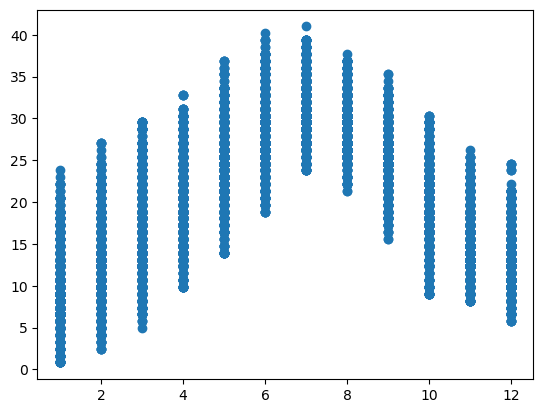

In [185]:
plt.scatter(df["month"],df["temp"])

データ件数: 17379
説明変数の列数: 9
説明変数:
['season', 'hour', 'holiday', 'workingday', 'weather', 'temp', 'feel_temp', 'humidity', 'windspeed']

学習データ数: 11972
テストデータ数: 3476

数値変数: ['hour', 'temp', 'feel_temp', 'humidity', 'windspeed']
カテゴリ変数: ['season', 'holiday', 'workingday', 'weather']

前処理後の特徴量数: 17

===== 特徴量重要度ランキング =====
 rank                 feature  importance
    1               num__hour    0.591841
    2               num__temp    0.140619
    3           num__humidity    0.063946
    4          num__feel_temp    0.040413
    5          num__windspeed    0.039976
    6   cat__workingday_False    0.033039
    7    cat__workingday_True    0.030864
    8      cat__season_winter    0.017807
    9       cat__weather_rain    0.013333
   10      cat__season_spring    0.008555
   11      cat__weather_clear    0.005152
   12      cat__season_summer    0.004801
   13      cat__weather_misty    0.003639
   14        cat__season_fall    0.002483
   15       cat__holiday_True    0.001830
   16      

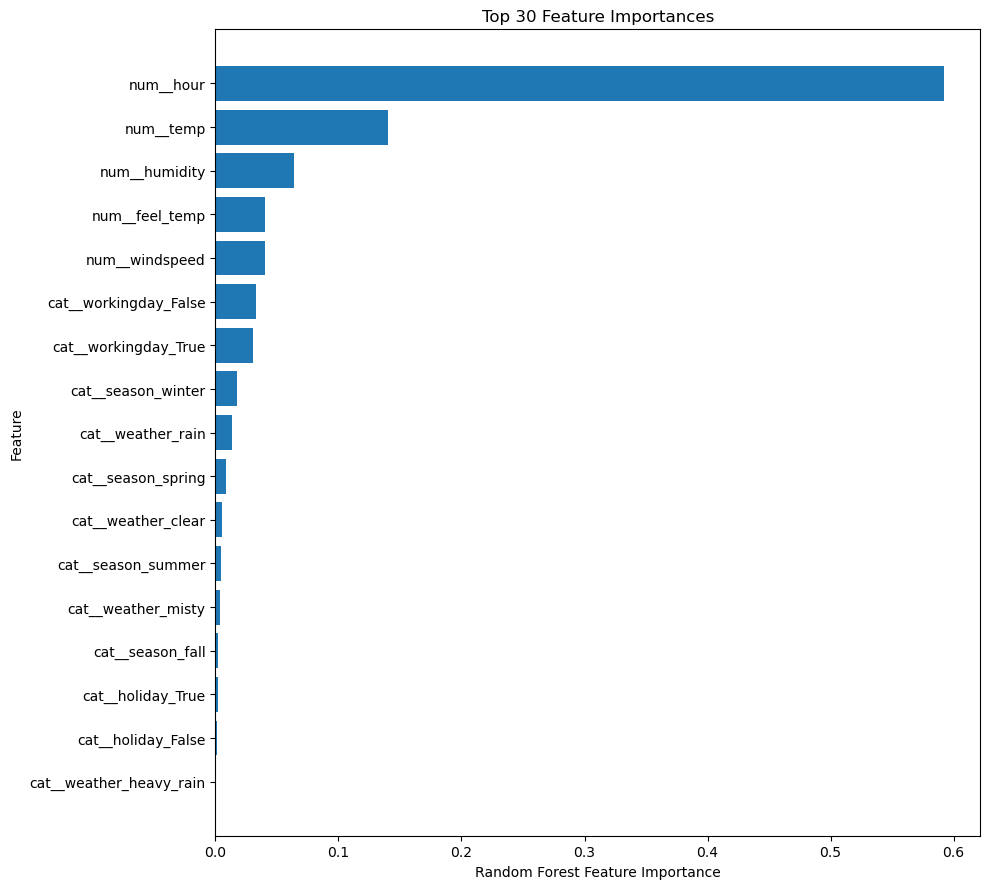


上位 5 特徴量でGPRを学習
TOP5_RBF_original              RMSE=125.587, MAE=90.761, R2=0.5019
TOP5_RBF_log1p                 RMSE=134.004, MAE=85.214, R2=0.4329
TOP5_Matern32_original         RMSE=124.722, MAE=89.587, R2=0.5088
TOP5_Matern32_log1p            RMSE=130.264, MAE=82.476, R2=0.4641
TOP5_Matern52_original         RMSE=125.321, MAE=90.292, R2=0.5040
TOP5_Matern52_log1p            RMSE=131.307, MAE=83.184, R2=0.4555

上位 10 特徴量でGPRを学習
TOP10_RBF_original             RMSE=121.708, MAE=87.687, R2=0.5322
TOP10_RBF_log1p                RMSE=129.076, MAE=80.996, R2=0.4739
TOP10_Matern32_original        RMSE=117.461, MAE=83.737, R2=0.5643
TOP10_Matern32_log1p           RMSE=122.474, MAE=76.386, R2=0.5263
TOP10_Matern52_original        RMSE=118.596, MAE=85.034, R2=0.5558
TOP10_Matern52_log1p           RMSE=124.077, MAE=77.410, R2=0.5138


===== モデル性能ランキング（RMSE順） =====
                  model  top_n   kernel target_transform       RMSE       MAE       R2
TOP10_Matern32_original     10 Matern32   

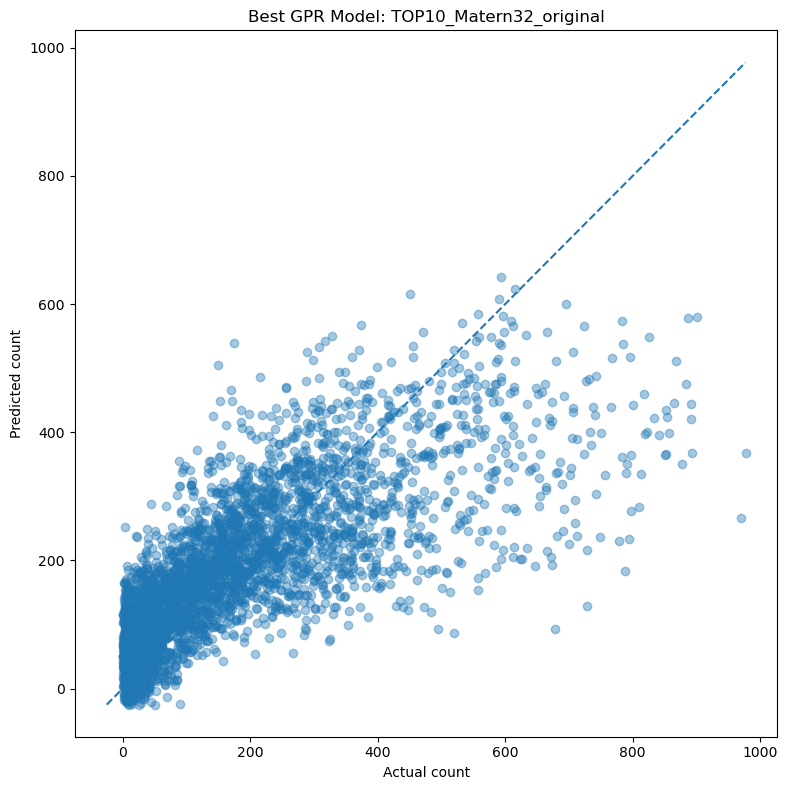


処理完了
保存ファイル:
- feature_importance.csv
- feature_importance.png
- gpr_model_comparison.csv
- gpr_best_predictions.csv
- gpr_actual_vs_predicted.png


In [188]:

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    ConstantKernel,
    RBF,
    Matern,
    WhiteKernel
)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

# ============================================================
# 1. データの読み込み
# ============================================================

data = fetch_openml(
    name="Bike_Sharing_Demand",
    version=2,
    as_frame=True
)

df = data.frame.copy()

target = "count"

if target not in df.columns:
    raise ValueError(f"目的変数 '{target}' が見つかりません。")

# 目的変数が欠損している行を削除
df = df.dropna(subset=[target]).copy()

y = pd.to_numeric(df[target], errors="raise")

# ============================================================
# 2. 説明変数の設定
# ============================================================

# countから直接計算できる情報は入力に使わない
# データセットに存在しない列は自動的に無視される
exclude_cols = [
    "count",

    # 日付・時刻関連の特徴量
    "year",
    "month",
    "weekday",
    "date",
    "datetime",
    "timestamp",
    "day",
]

X = df.drop(
    columns=[c for c in exclude_cols if c in df.columns]
).copy()

print("データ件数:", len(X))
print("説明変数の列数:", X.shape[1])
print("説明変数:")
print(X.columns.tolist())


# ============================================================
# 3. True / False を0 / 1に変換
# ============================================================

for col in X.columns:

    # bool型
    if pd.api.types.is_bool_dtype(X[col]):
        X[col] = X[col].astype(float)

    # 文字列のTrue / False
    elif X[col].dtype == "object":
        values = set(
            X[col].dropna().astype(str).str.lower().unique()
        )

        if values and values.issubset({"true", "false"}):
            X[col] = (
                X[col]
                .astype(str)
                .str.lower()
                .map({"false": 0.0, "true": 1.0})
            )


# ============================================================
# 4. 学習データとテストデータに分割
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
mask = X_train[X_train["windspeed"] ==0].index
X_train = X_train.drop(mask)
y_train = y_train.drop(mask)

mask = X_train[X_train["humidity"] ==0].index
X_train = X_train.drop(mask)
y_train = y_train.drop(mask)

mask = X_train[X_train["humidity"] == X_train["humidity"].max()].index
X_train = X_train.drop(mask)
y_train = y_train.drop(mask)



print("\n学習データ数:", len(X_train))
print("テストデータ数:", len(X_test))

# windspeed == 0 の行は削除しない
# 風速0は実際に起こり得るため

# ============================================================
# 5. 数値変数・カテゴリ変数の判定
# ============================================================

numeric_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = [
    col for col in X_train.columns
    if col not in numeric_cols
]

print("\n数値変数:", numeric_cols)
print("カテゴリ変数:", categorical_cols)

# ============================================================
# 6. 前処理
#    数値変数：中央値補完 + 標準化
#    カテゴリ変数：最頻値補完 + One-Hot Encoding
# ============================================================

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

X_train_enc = preprocessor.fit_transform(X_train)
X_test_enc = preprocessor.transform(X_test)

feature_names = np.array(
    preprocessor.get_feature_names_out()
)

print("\n前処理後の特徴量数:", len(feature_names))

# ============================================================
# 7. ランダムフォレストで特徴量重要度を計算
# ============================================================

rf = RandomForestRegressor(
    n_estimators=500,
    random_state=42,
    n_jobs=-1,
    max_features=1.0
)

rf.fit(X_train_enc, y_train)

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": rf.feature_importances_
}).sort_values(
    "importance",
    ascending=False
).reset_index(drop=True)

importance_df.insert(
    0,
    "rank",
    np.arange(1, len(importance_df) + 1)
)

print("\n===== 特徴量重要度ランキング =====")
print(importance_df.to_string(index=False))

importance_df.to_csv(
    "feature_importance.csv",
    index=False,
    encoding="utf-8-sig"
)

# 特徴量重要度の上位30個を図示
top_plot = importance_df.head(30).sort_values(
    "importance",
    ascending=True
)

plt.figure(figsize=(10, 9))
plt.barh(
    top_plot["feature"],
    top_plot["importance"]
)
plt.xlabel("Random Forest Feature Importance")
plt.ylabel("Feature")
plt.title("Top 30 Feature Importances")
plt.tight_layout()
plt.savefig(
    "feature_importance.png",
    dpi=200
)
plt.show()

# ============================================================
# 8. GPRの設定
# ============================================================

# GPRは学習データ数の増加に伴って計算量が急増するため、
# 学習データから最大800件を抽出して学習する
GPR_TRAIN_SIZE = 900

rng = np.random.default_rng(56)

n_gpr_train = min(
    GPR_TRAIN_SIZE,
    len(X_train_enc)
)

sample_idx = rng.choice(
    len(X_train_enc),
    size=n_gpr_train,
    replace=False
)

# 比較する特徴量数
TOP_N_LIST = [5,10]

# 比較するカーネル
KERNELS = {
    "RBF": lambda: (
        ConstantKernel(
            1.0,
            (1e-3, 1e3)
        )
        * RBF(
            length_scale=1.0,
            length_scale_bounds=(1e-2, 1e2)
        )
        + WhiteKernel(
            noise_level=1.0,
            noise_level_bounds=(1e-3, 1e2)
        )
    ),

    "Matern32": lambda: (
        ConstantKernel(
            1.0,
            (1e-3, 1e3)
        )
        * Matern(
            length_scale=1.0,
            length_scale_bounds=(1e-2, 1e2),
            nu=1.5
        )
        + WhiteKernel(
            noise_level=1.0,
            noise_level_bounds=(1e-3, 1e2)
        )
    ),

    "Matern52": lambda: (
        ConstantKernel(
            1.0,
            (1e-3, 1e3)
        )
        * Matern(
            length_scale=1.0,
            length_scale_bounds=(1e-2, 1e2),
            nu=2.5
        )
        + WhiteKernel(
            noise_level=1.0,
            noise_level_bounds=(1e-3, 1e2)
        )
    )
}

# ============================================================
# 9. 特徴量数・カーネル・目的変数変換を比較
# ============================================================

results = []
predictions = {}

for top_n in TOP_N_LIST:

    # 存在する特徴量数を超えないようにする
    n_features = min(top_n, len(importance_df))

    selected_features = (
        importance_df
        .head(n_features)["feature"]
        .tolist()
    )

    # 特徴量名から列番号を取得
    selected_indices = [
        np.where(feature_names == name)[0][0]
        for name in selected_features
    ]

    X_train_selected = X_train_enc[:, selected_indices]
    X_test_selected = X_test_enc[:, selected_indices]

    X_gpr_train = X_train_selected[sample_idx]

    y_gpr_original = y_train.iloc[sample_idx].to_numpy()

    print(
        f"\n{'=' * 60}\n"
        f"上位 {n_features} 特徴量でGPRを学習\n"
        f"{'=' * 60}"
    )

    for kernel_name, kernel_factory in KERNELS.items():

        for use_log in [False, True]:

            transform_name = (
                "log1p" if use_log else "original"
            )

            # countをそのまま使うか、対数変換するか
            if use_log:
                y_gpr_train = np.log1p(
                    np.maximum(y_gpr_original, 0)
                )
            else:
                y_gpr_train = y_gpr_original

            gpr = GaussianProcessRegressor(
                kernel=kernel_factory(),
                normalize_y=True,
                n_restarts_optimizer=1,
                random_state=42
            )

            gpr.fit(
                X_gpr_train,
                y_gpr_train
            )

            # 予測
            y_pred_model = gpr.predict(
                X_test_selected
            )

            # 対数変換した場合は元の単位に戻す
            if use_log:
                y_pred = np.expm1(y_pred_model)
                y_pred = np.maximum(y_pred, 0)
            else:
                y_pred = y_pred_model

            # 元のcountスケールで評価
            rmse = np.sqrt(
                mean_squared_error(y_test, y_pred)
            )

            mae = mean_absolute_error(
                y_test,
                y_pred
            )

            r2 = r2_score(
                y_test,
                y_pred
            )

            model_name = (
                f"TOP{n_features}_"
                f"{kernel_name}_"
                f"{transform_name}"
            )

            results.append({
                "model": model_name,
                "top_n": n_features,
                "kernel": kernel_name,
                "target_transform": transform_name,
                "RMSE": rmse,
                "MAE": mae,
                "R2": r2,
                "optimized_kernel": str(gpr.kernel_)
            })

            predictions[model_name] = y_pred

            print(
                f"{model_name:30s} "
                f"RMSE={rmse:.3f}, "
                f"MAE={mae:.3f}, "
                f"R2={r2:.4f}"
            )

# ============================================================
# 10. モデル性能を比較
# ============================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "RMSE",
    ascending=True
).reset_index(drop=True)

print("\n\n===== モデル性能ランキング（RMSE順） =====")

print(
    results_df[
        [
            "model",
            "top_n",
            "kernel",
            "target_transform",
            "RMSE",
            "MAE",
            "R2"
        ]
    ].to_string(index=False)
)

results_df.to_csv(
    "gpr_model_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 11. 最良モデルの予測結果を保存
# ============================================================

best_model_name = results_df.iloc[0]["model"]
best_prediction = predictions[best_model_name]

print("\n===== 最良モデル =====")
print("モデル:", best_model_name)
print("RMSE:", results_df.iloc[0]["RMSE"])
print("MAE:", results_df.iloc[0]["MAE"])
print("R2:", results_df.iloc[0]["R2"])

prediction_df = pd.DataFrame({
    "actual_count": y_test.to_numpy(),
    "predicted_count": best_prediction,
    "residual": y_test.to_numpy() - best_prediction
})

prediction_df.to_csv(
    "gpr_best_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 12. 実測値と予測値の散布図
# ============================================================

plt.figure(figsize=(8, 8))

plt.scatter(
    y_test,
    best_prediction,
    alpha=0.4
)

min_value = min(
    float(y_test.min()),
    float(np.min(best_prediction))
)

max_value = max(
    float(y_test.max()),
    float(np.max(best_prediction))
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual count")
plt.ylabel("Predicted count")
plt.title(f"Best GPR Model: {best_model_name}")
plt.tight_layout()
plt.savefig(
    "gpr_actual_vs_predicted.png",
    dpi=200
)
plt.show()

print("\n処理完了")
print("保存ファイル:")
print("- feature_importance.csv")
print("- feature_importance.png")
print("- gpr_model_comparison.csv")
print("- gpr_best_predictions.csv")
print("- gpr_actual_vs_predicted.png")


データ件数: 17379
説明変数の列数: 9
説明変数:
['season', 'hour', 'holiday', 'workingday', 'weather', 'temp', 'feel_temp', 'humidity', 'windspeed']

学習データ数: 11972
テストデータ数: 3476

数値変数: ['hour', 'temp', 'feel_temp', 'humidity', 'windspeed']
カテゴリ変数: ['season', 'holiday', 'workingday', 'weather']

前処理後の特徴量数: 17

===== 特徴量重要度ランキング =====
 rank                 feature  importance
    1               num__hour    0.591841
    2               num__temp    0.140619
    3           num__humidity    0.063946
    4          num__feel_temp    0.040413
    5          num__windspeed    0.039976
    6   cat__workingday_False    0.033039
    7    cat__workingday_True    0.030864
    8      cat__season_winter    0.017807
    9       cat__weather_rain    0.013333
   10      cat__season_spring    0.008555
   11      cat__weather_clear    0.005152
   12      cat__season_summer    0.004801
   13      cat__weather_misty    0.003639
   14        cat__season_fall    0.002483
   15       cat__holiday_True    0.001830
   16      

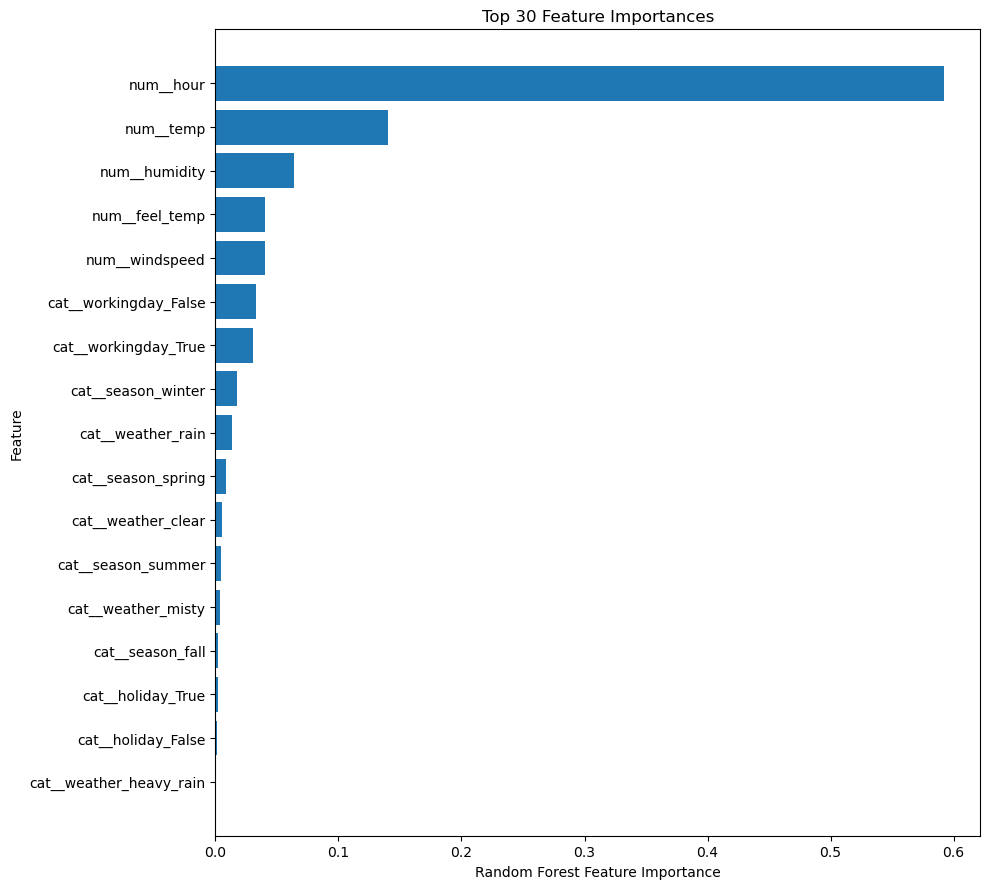


上位 5 特徴量でJAX Adam-GPRを学習
TOP5_RBF_original              RMSE=125.657, MAE=90.870, R2=0.5014 | signal_var=0.5600, length=1.8475, noise_var=0.5180
TOP5_RBF_log1p                 RMSE=134.013, MAE=85.217, R2=0.4328 | signal_var=0.5442, length=0.6962, noise_var=0.2372
TOP5_Matern32_original         RMSE=124.648, MAE=89.709, R2=0.5093 | signal_var=0.4267, length=1.6046, noise_var=0.4665
TOP5_Matern32_log1p            RMSE=130.321, MAE=82.512, R2=0.4637 | signal_var=0.6162, length=1.0045, noise_var=0.2143
TOP5_Matern52_original         RMSE=125.366, MAE=90.482, R2=0.5037 | signal_var=0.4605, length=1.9073, noise_var=0.5009
TOP5_Matern52_log1p            RMSE=131.340, MAE=83.202, R2=0.4552 | signal_var=0.5797, length=0.8782, noise_var=0.2254

上位 10 特徴量でJAX Adam-GPRを学習
TOP10_RBF_original             RMSE=122.159, MAE=88.721, R2=0.5287 | signal_var=0.4503, length=0.9618, noise_var=0.3657
TOP10_RBF_log1p                RMSE=129.058, MAE=80.986, R2=0.4740 | signal_var=0.6928, length=0.7833, nois

In [ ]:

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
import jax
import jax.numpy as jnp
import optax
from jax.scipy.linalg import solve_triangular

jax.config.update("jax_enable_x64", True)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# ============================================================
# 1. データの読み込み
# ============================================================

data = fetch_openml(
    name="Bike_Sharing_Demand",
    version=2,
    as_frame=True
)

df = data.frame.copy()

target = "count"

if target not in df.columns:
    raise ValueError(f"目的変数 '{target}' が見つかりません。")

# 目的変数が欠損している行を削除
df = df.dropna(subset=[target]).copy()

y = pd.to_numeric(df[target], errors="raise")

# ============================================================
# 2. 説明変数の設定
# ============================================================

# countから直接計算できる情報は入力に使わない
# データセットに存在しない列は自動的に無視される
exclude_cols = [
    "count",

    # 日付・時刻関連の特徴量
    "year",
    "month",
    "weekday",
    "date",
    "datetime",
    "timestamp",
    "day",
]

X = df.drop(
    columns=[c for c in exclude_cols if c in df.columns]
).copy()

print("データ件数:", len(X))
print("説明変数の列数:", X.shape[1])
print("説明変数:")
print(X.columns.tolist())


# ============================================================
# 3. True / False を0 / 1に変換
# ============================================================

for col in X.columns:

    # bool型
    if pd.api.types.is_bool_dtype(X[col]):
        X[col] = X[col].astype(float)

    # 文字列のTrue / False
    elif X[col].dtype == "object":
        values = set(
            X[col].dropna().astype(str).str.lower().unique()
        )

        if values and values.issubset({"true", "false"}):
            X[col] = (
                X[col]
                .astype(str)
                .str.lower()
                .map({"false": 0.0, "true": 1.0})
            )


# ============================================================
# 4. 学習データとテストデータに分割
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
mask = X_train[X_train["windspeed"] ==0].index
X_train = X_train.drop(mask)
y_train = y_train.drop(mask)

mask = X_train[X_train["humidity"] ==0].index
X_train = X_train.drop(mask)
y_train = y_train.drop(mask)

mask = X_train[X_train["humidity"] == X_train["humidity"].max()].index
X_train = X_train.drop(mask)
y_train = y_train.drop(mask)



print("\n学習データ数:", len(X_train))
print("テストデータ数:", len(X_test))


# ============================================================
# 5. 数値変数・カテゴリ変数の判定
# ============================================================

numeric_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = [
    col for col in X_train.columns
    if col not in numeric_cols
]

print("\n数値変数:", numeric_cols)
print("カテゴリ変数:", categorical_cols)

# ============================================================
# 6. 前処理
#    数値変数：中央値補完 + 標準化
#    カテゴリ変数：最頻値補完 + One-Hot Encoding
# ============================================================

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

X_train_enc = preprocessor.fit_transform(X_train)
X_test_enc = preprocessor.transform(X_test)

feature_names = np.array(
    preprocessor.get_feature_names_out()
)

print("\n前処理後の特徴量数:", len(feature_names))

# ============================================================
# 7. ランダムフォレストで特徴量重要度を計算
# ============================================================

rf = RandomForestRegressor(
    n_estimators=500,
    random_state=42,
    n_jobs=-1,
    max_features=1.0
)

rf.fit(X_train_enc, y_train)

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": rf.feature_importances_
}).sort_values(
    "importance",
    ascending=False
).reset_index(drop=True)

importance_df.insert(
    0,
    "rank",
    np.arange(1, len(importance_df) + 1)
)

print("\n===== 特徴量重要度ランキング =====")
print(importance_df.to_string(index=False))

importance_df.to_csv(
    "feature_importance.csv",
    index=False,
    encoding="utf-8-sig"
)

# 特徴量重要度の上位30個を図示
top_plot = importance_df.head(30).sort_values(
    "importance",
    ascending=True
)

plt.figure(figsize=(10, 9))
plt.barh(
    top_plot["feature"],
    top_plot["importance"]
)
plt.xlabel("Random Forest Feature Importance")
plt.ylabel("Feature")
plt.title("Top 30 Feature Importances")
plt.tight_layout()
plt.savefig(
    "feature_importance.png",
    dpi=200
)
plt.show()

# ============================================================
# 8. JAXによるGPR設定
#    ・ハイパーパラメータを対数空間で最適化
#    ・初期値は log(theta) ∈ [-2, 0]
#    ・最適化は Adam
#    ・Jeffreys prior p(theta) ∝ 1/theta を使用
# ============================================================

GPR_TRAIN_SIZE = 900
rng = np.random.default_rng(56)
n_gpr_train = min(GPR_TRAIN_SIZE, len(X_train_enc))
sample_idx = rng.choice(len(X_train_enc), size=n_gpr_train, replace=False)

TOP_N_LIST = [5, 10]

# 最適化設定
INITIAL_LOG_MIN = -2.0
INITIAL_LOG_MAX = 0.0
# 初期値は[-2, 0]から選ぶ。最適化中は探索範囲を広げる。
OPT_LOG_MIN = -8.0
OPT_LOG_MAX = 8.0
INITIAL_LOG_PARAMS = [-1.0, -1.0, -1.0]  # 各要素は[-2, 0]内: [log(signal variance), log(length scale), log(noise variance)]
ADAM_LR = 0.03
ADAM_STEPS = 250
JITTER = 1e-6

# Jeffreys prior:
# p(theta) ∝ 1/theta なので log(theta)=eta に変数変換すると
# p(eta)=p(theta)*|dtheta/deta| ∝ (1/theta)*theta = constant。
# よって log パラメータ空間では prior の負の対数は定数であり、
# MAP目的関数は負の対数周辺尤度 (NLL) と定数差しかない。
# 以下では log パラメータ空間で NLL を最小化し、Jeffreys prior を正しく反映する。


def jax_kernel_matrix(X1, X2, log_params, kernel_name):
    """log_params = [log(signal variance), log(length scale), log(noise variance)]"""
    signal_var = jnp.exp(log_params[0])
    length_scale = jnp.exp(log_params[1])
    x1_sq = jnp.sum(X1 * X1, axis=1, keepdims=True)
    x2_sq = jnp.sum(X2 * X2, axis=1, keepdims=True).T
    dist2 = jnp.maximum(x1_sq + x2_sq - 2.0 * (X1 @ X2.T), 0.0)
    r = jnp.sqrt(jnp.maximum(dist2, 1e-15)) / length_scale

    if kernel_name == "RBF":
        base = jnp.exp(-0.5 * dist2 / (length_scale ** 2))
    elif kernel_name == "Matern32":
        z = jnp.sqrt(3.0) * r
        base = (1.0 + z) * jnp.exp(-z)
    elif kernel_name == "Matern52":
        z = jnp.sqrt(5.0) * r
        base = (1.0 + z + (z ** 2) / 3.0) * jnp.exp(-z)
    else:
        raise ValueError(f"未対応のカーネル: {kernel_name}")
    return signal_var * base


def fit_gpr_adam_jax(X_np, y_np, kernel_name):
    """Exact GPRをJAX + Optax Adamで学習する。"""
    X_t = jnp.asarray(np.asarray(X_np), dtype=jnp.float64)
    y_np = np.asarray(y_np, dtype=float).reshape(-1)

    # normalize_y=True 相当：目的変数を標準化
    y_mean = float(np.mean(y_np))
    y_std = float(np.std(y_np))
    if not np.isfinite(y_std) or y_std < 1e-12:
        y_std = 1.0
    y_t = jnp.asarray((y_np - y_mean) / y_std, dtype=jnp.float64)

    # 初期値は log(theta) ∈ [-2, 0]。3パラメータとも範囲内。
    initial_log_params = jnp.clip(jnp.asarray(INITIAL_LOG_PARAMS, dtype=jnp.float64), INITIAL_LOG_MIN, INITIAL_LOG_MAX)
    n = X_t.shape[0]
    identity = jnp.eye(n, dtype=jnp.float64)

    def negative_log_marginal_likelihood(log_params):
        noise_var = jnp.exp(log_params[2])
        K = jax_kernel_matrix(X_t, X_t, log_params, kernel_name)
        K = K + (noise_var + JITTER) * identity
        L = jnp.linalg.cholesky(K)
        # L v = y、L^T alpha = v
        v = solve_triangular(L, y_t, lower=True)
        alpha = solve_triangular(L.T, v, lower=False)
        nll = (
            0.5 * jnp.dot(y_t, alpha)
            + jnp.sum(jnp.log(jnp.diag(L)))
            + 0.5 * n * jnp.log(2.0 * jnp.pi) + jnp.sum(jnp.exp(log_params))
        )
        return nll

    # Jeffreys prior p(theta) ∝ 1/theta。
    # eta=log(theta) と変数変換すると p(eta) ∝ 1 となるため、
    # eta空間での負の対数事前項は定数。MAP目的関数はNLLと定数差のみ。
    optimizer = optax.adam(learning_rate=ADAM_LR)
    opt_state = optimizer.init(initial_log_params)

    @jax.jit
    def train_step(log_params, opt_state):
        loss, grads = jax.value_and_grad(negative_log_marginal_likelihood)(log_params)
        updates, opt_state = optimizer.update(grads, opt_state, log_params)
        log_params = optax.apply_updates(log_params, updates)
        log_params = jnp.clip(log_params, OPT_LOG_MIN, OPT_LOG_MAX)
        return log_params, opt_state, loss

    log_params = initial_log_params
    loss_history = []
    for _ in range(ADAM_STEPS):
        log_params, opt_state, loss = train_step(log_params, opt_state)
        loss_history.append(float(loss))

    # 学習済みパラメータから予測用のCholesky分解を計算
    noise_var = jnp.exp(log_params[2])
    K_train = jax_kernel_matrix(X_t, X_t, log_params, kernel_name)
    K_train = K_train + (noise_var + JITTER) * identity
    L_train = jnp.linalg.cholesky(K_train)
    v_train = solve_triangular(L_train, y_t, lower=True)
    alpha_train = solve_triangular(L_train.T, v_train, lower=False)

    return {
        "X_train": X_t,
        "L_train": L_train,
        "alpha_train": alpha_train,
        "log_params": log_params,
        "y_mean": y_mean,
        "y_std": y_std,
        "loss_history": loss_history,
    }


def predict_gpr_adam_jax(model, X_new, kernel_name):
    X_new_t = jnp.asarray(np.asarray(X_new), dtype=jnp.float64)
    K_cross = jax_kernel_matrix(
        X_new_t, model["X_train"], model["log_params"], kernel_name
    )
    pred_std = K_cross @ model["alpha_train"]
    pred = np.asarray(pred_std).reshape(-1)
    return pred * model["y_std"] + model["y_mean"]


# ============================================================
# 9. 特徴量数・カーネル・目的変数変換を比較
# ============================================================

results = []
predictions = {}

for top_n in TOP_N_LIST:
    n_features = min(top_n, len(importance_df))
    selected_features = importance_df.head(n_features)["feature"].tolist()
    selected_indices = [np.where(feature_names == name)[0][0] for name in selected_features]

    X_train_selected = X_train_enc[:, selected_indices]
    X_test_selected = X_test_enc[:, selected_indices]
    X_gpr_train = X_train_selected[sample_idx]
    y_gpr_original = y_train.iloc[sample_idx].to_numpy()

    print(f"\n{'=' * 60}\n上位 {n_features} 特徴量でJAX Adam-GPRを学習\n{'=' * 60}")

    for kernel_name in ["RBF", "Matern32", "Matern52"]:
        for use_log in [False, True]:
            transform_name = "log1p" if use_log else "original"
            if use_log:
                y_gpr_train = np.log1p(np.maximum(y_gpr_original, 0))
            else:
                y_gpr_train = y_gpr_original

            gpr_model = fit_gpr_adam_jax(X_gpr_train, y_gpr_train, kernel_name)
            y_pred_model = predict_gpr_adam_jax(gpr_model, X_test_selected, kernel_name)

            if use_log:
                y_pred = np.maximum(np.expm1(y_pred_model), 0)
            else:
                y_pred = y_pred_model

            rmse = np.sqrt(mean_squared_error(y_test, y_pred))
            mae = mean_absolute_error(y_test, y_pred)
            r2 = r2_score(y_test, y_pred)

            hp = np.exp(np.asarray(gpr_model["log_params"]))
            model_name = f"TOP{n_features}_{kernel_name}_{transform_name}"
            results.append({
                "model": model_name,
                "top_n": n_features,
                "kernel": kernel_name,
                "target_transform": transform_name,
                "RMSE": rmse,
                "MAE": mae,
                "R2": r2,
                "signal_variance": hp[0],
                "length_scale": hp[1],
                "noise_variance": hp[2],
                "final_negative_log_marginal_likelihood": gpr_model["loss_history"][-1],
                "initial_log_parameter_range": f"[{INITIAL_LOG_MIN}, {INITIAL_LOG_MAX}]",
                "optimization_log_parameter_bounds": f"[{OPT_LOG_MIN}, {OPT_LOG_MAX}]",
                "optimizer": "JAX Optax Adam",
                "prior": "Jeffreys p(theta) proportional to 1/theta",
            })
            predictions[model_name] = y_pred
            print(
                f"{model_name:30s} RMSE={rmse:.3f}, MAE={mae:.3f}, R2={r2:.4f} | "
                f"signal_var={hp[0]:.4f}, length={hp[1]:.4f}, noise_var={hp[2]:.4f}"
            )

# ============================================================
# 10. モデル性能を比較
# ============================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "RMSE",
    ascending=True
).reset_index(drop=True)

print("\n\n===== モデル性能ランキング（RMSE順） =====")

print(
    results_df[
        [
            "model",
            "top_n",
            "kernel",
            "target_transform",
            "RMSE",
            "MAE",
            "R2"
        ]
    ].to_string(index=False)
)

results_df.to_csv(
    "gpr_model_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 11. 最良モデルの予測結果を保存
# ============================================================

best_model_name = results_df.iloc[0]["model"]
best_prediction = predictions[best_model_name]

print("\n===== 最良モデル =====")
print("モデル:", best_model_name)
print("RMSE:", results_df.iloc[0]["RMSE"])
print("MAE:", results_df.iloc[0]["MAE"])
print("R2:", results_df.iloc[0]["R2"])

prediction_df = pd.DataFrame({
    "actual_count": y_test.to_numpy(),
    "predicted_count": best_prediction,
    "residual": y_test.to_numpy() - best_prediction
})

prediction_df.to_csv(
    "gpr_best_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 12. 実測値と予測値の散布図
# ============================================================

plt.figure(figsize=(8, 8))

plt.scatter(
    y_test,
    best_prediction,
    alpha=0.4
)

min_value = min(
    float(y_test.min()),
    float(np.min(best_prediction))
)

max_value = max(
    float(y_test.max()),
    float(np.max(best_prediction))
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual count")
plt.ylabel("Predicted count")
plt.title(f"Best GPR Model: {best_model_name}")
plt.tight_layout()
plt.savefig(
    "gpr_actual_vs_predicted.png",
    dpi=200
)
plt.show()

print("\n処理完了")
print("保存ファイル:")
print("- feature_importance.csv")
print("- feature_importance.png")
print("- gpr_model_comparison.csv")
print("- gpr_best_predictions.csv")
print("- gpr_actual_vs_predicted.png")
